# 01 · Exploring the HDFS logs

**Goal:** understand the data before building anything on it. This notebook answers:

1. What does the data look like after the adapter (`logad ingest`) converted it?
2. How are lines spread over levels, components and time?
3. How many blocks (sessions) are anomalous? *(This decides how we evaluate later.)*
4. How do anomalous blocks differ from normal ones?
5. Why do we need a log parser (Drain, Stage 2)?

**Before running:** from the project root, in the activated venv:

```powershell
logad download --config configs/hdfs.yaml   # ~187 MB from Zenodo, checksum-verified
logad ingest   --config configs/hdfs.yaml   # → artifacts/hdfs/logs.parquet
```

Queries use **DuckDB**: SQL straight on the Parquet file, without loading 11M rows into pandas.
Labels are used here only to *look*; no model ever trains on them.

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt

from logad.config import load_config

# Run from the project root, whether the notebook was started there or in notebooks/.
if not (Path.cwd() / "configs").is_dir():
    os.chdir(Path.cwd().parent)

config = load_config("configs/hdfs.yaml")
LOGS = Path(config["paths"]["artifacts_dir"]) / "logs.parquet"
REPORTS = Path(config["paths"]["reports_dir"])
REPORTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 4), "figure.dpi": 110, "axes.grid": True})

con = duckdb.connect()  # in-memory database: nothing is written to disk
con.sql(f"CREATE VIEW logs AS SELECT * FROM '{LOGS.as_posix()}'")


def q(sql):
    # Run SQL and return a pandas DataFrame (pretty-printed by Jupyter).
    return con.sql(sql).df()


def save(fig, name):
    # Save a chart into reports/hdfs/ so the README can show it.
    fig.tight_layout()
    fig.savefig(REPORTS / name, bbox_inches="tight")

## 1. First look

The adapter writes **one row per (line, block)**. A line that mentions several blocks
(e.g. *"ask … to delete blk_1 blk_2 …"*, which appears in the 2k sample) becomes one row per
block, all with the same `line_id`. In the full HDFS_v1 file every line mentions exactly one
block, so `rows == lines` below.

In [2]:
q("SELECT * FROM logs LIMIT 5")

,line_id,timestamp,source,level,component,message,group_id,label
0,0,2008-11-09 20:35:18,hdfs,INFO,dfs.DataNode$DataXceiver,Receiving block blk_-1608999687919862906 src: ...,blk_-1608999687919862906,0
1,1,2008-11-09 20:35:18,hdfs,INFO,dfs.FSNamesystem,BLOCK* NameSystem.allocateBlock: /mnt/hadoop/m...,blk_-1608999687919862906,0
2,2,2008-11-09 20:35:19,hdfs,INFO,dfs.DataNode$DataXceiver,Receiving block blk_-1608999687919862906 src: ...,blk_-1608999687919862906,0
3,3,2008-11-09 20:35:19,hdfs,INFO,dfs.DataNode$DataXceiver,Receiving block blk_-1608999687919862906 src: ...,blk_-1608999687919862906,0
4,4,2008-11-09 20:35:19,hdfs,INFO,dfs.DataNode$PacketResponder,PacketResponder 1 for block blk_-1608999687919...,blk_-1608999687919862906,0


In [3]:
q("""
    SELECT count(*)                  AS rows,
           count(DISTINCT line_id)   AS lines,
           count(DISTINCT group_id)  AS blocks,
           min(timestamp)            AS first_line,
           max(timestamp)            AS last_line,
           max(timestamp) - min(timestamp) AS time_span
    FROM logs
""")

,rows,lines,blocks,first_line,last_line,time_span
0,11175629,11175629,575061,2008-11-09 20:35:18,2008-11-11 11:16:28,1 days 14:41:10


For line-level questions (levels, components, time) we want each raw line counted **once**,
so we build a `lines` table with one row per `line_id`. For session-level questions we build a
`blocks` table with one row per block. Both are stored in DuckDB's memory for fast queries.

In [4]:
con.sql("""
    CREATE OR REPLACE TABLE lines AS
    SELECT DISTINCT ON (line_id) line_id, timestamp, level, component, message
    FROM logs
""")
con.sql("""
    CREATE OR REPLACE TABLE blocks AS
    SELECT group_id,
           any_value(label)                         AS label,
           count(*)                                 AS n_lines,
           count(*) FILTER (WHERE level = 'WARN')   AS n_warn,
           max(timestamp) - min(timestamp)          AS duration
    FROM logs
    WHERE group_id IS NOT NULL
    GROUP BY group_id
""")
q("SELECT * FROM blocks LIMIT 5")

,group_id,label,n_lines,n_warn,duration
0,blk_1687481880071005767,0,19,0,0 days 00:45:24
1,blk_-1768526435413310884,0,19,0,0 days 00:47:18
2,blk_1883236876823501303,0,19,0,0 days 00:41:45
3,blk_-2415709352569601287,0,19,0,0 days 00:43:06
4,blk_242273883899580185,0,19,0,0 days 00:42:12


## 2. Levels, components and time

In [5]:
q("""
    SELECT level, count(*) AS lines, round(100 * count(*) / sum(count(*)) OVER (), 2) AS pct
    FROM lines GROUP BY level ORDER BY lines DESC
""")

,level,lines,pct
0,INFO,10812836,96.75
1,WARN,362793,3.25


HDFS only logs `INFO` and `WARN` here, with no `ERROR` lines. So **we can't simply grep for
errors**: anomalies have to be found from *patterns* of normal-looking lines.

,component,lines
0,dfs.FSNamesystem,3700245
1,dfs.DataNode$PacketResponder,3413350
2,dfs.DataNode$DataXceiver,2518678
3,dfs.FSDataset,1407597
4,dfs.DataBlockScanner,120046
5,dfs.DataNode,7002
6,dfs.DataNode$DataTransfer,6946
7,dfs.DataNode$BlockReceiver,1718
8,dfs.PendingReplicationBlocks$PendingReplicatio...,47


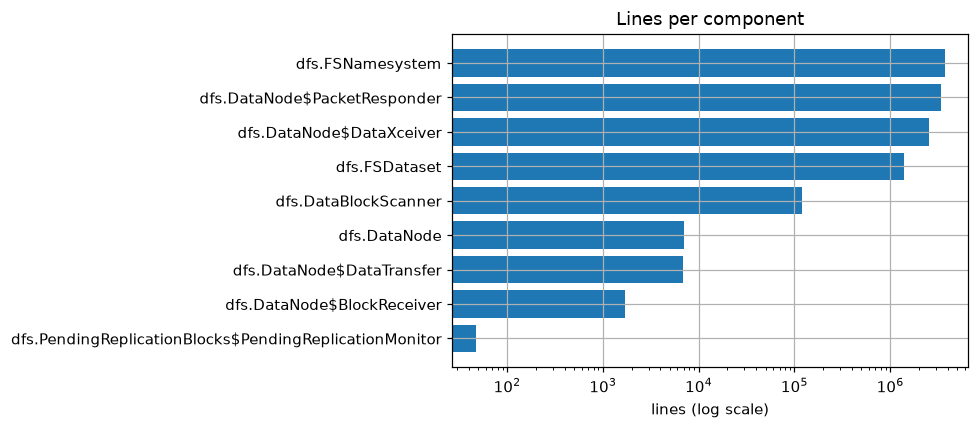

In [6]:
components = q("""
    SELECT component, count(*) AS lines
    FROM lines GROUP BY component ORDER BY lines DESC
""")
fig, ax = plt.subplots()
ax.barh(components["component"][::-1], components["lines"][::-1])
ax.set_xscale("log")
ax.set_xlabel("lines (log scale)")
ax.set_title("Lines per component")
save(fig, "eda_components.png")
components

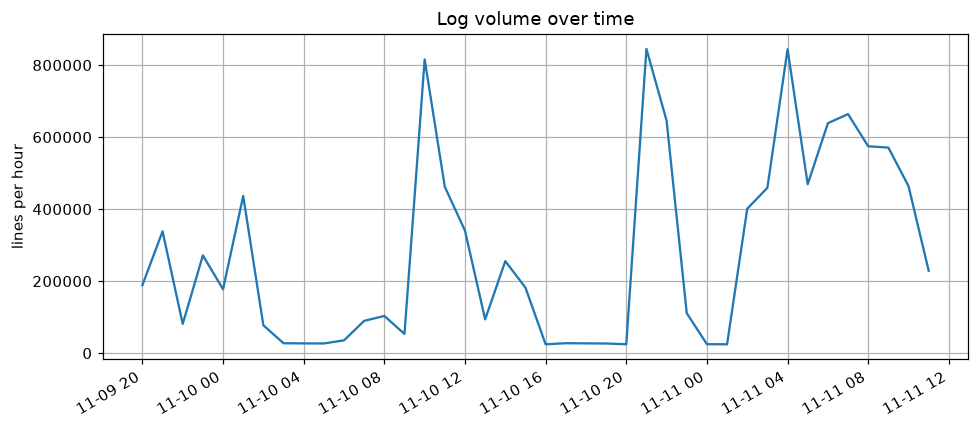

In [7]:
per_hour = q("""
    SELECT date_trunc('hour', timestamp) AS hour, count(*) AS lines
    FROM lines GROUP BY hour ORDER BY hour
""")
fig, ax = plt.subplots()
ax.plot(per_hour["hour"], per_hour["lines"])
ax.set_ylabel("lines per hour")
ax.set_title("Log volume over time")
fig.autofmt_xdate()
save(fig, "eda_lines_per_hour.png")

## 3. Labels: how many blocks are anomalous?

This is the most important number in the notebook: it decides how we evaluate models.

In [8]:
label_counts = q("""
    SELECT CASE label WHEN 1 THEN 'anomaly' WHEN 0 THEN 'normal' ELSE 'unlabelled' END AS label,
           count(*) AS blocks,
           round(100 * count(*) / sum(count(*)) OVER (), 2) AS pct
    FROM blocks GROUP BY ALL ORDER BY blocks DESC
""")
label_counts

,label,blocks,pct
0,normal,558223,97.07
1,anomaly,16838,2.93


The classes are **heavily imbalanced**. A "model" that calls *every* block normal would score
~97% accuracy while catching zero anomalies. That's why Stage 5 uses **precision, recall
and F1** on the anomaly class, plus precision-recall curves, and never plain accuracy.

## 4. How do anomalous blocks differ from normal ones?

### 4a. Block length

In [9]:
q("""
    SELECT label,
           count(*)                         AS blocks,
           round(avg(n_lines), 1)           AS mean_lines,
           median(n_lines)                  AS median_lines,
           min(n_lines)                     AS min_lines,
           max(n_lines)                     AS max_lines,
           round(100 * avg((n_warn > 0)::INT), 1) AS pct_with_warn
    FROM blocks GROUP BY label ORDER BY label
""")

,label,blocks,mean_lines,median_lines,min_lines,max_lines,pct_with_warn
0,0,558223,19.5,19.0,13,298,22.6
1,1,16838,17.1,20.0,2,284,48.2


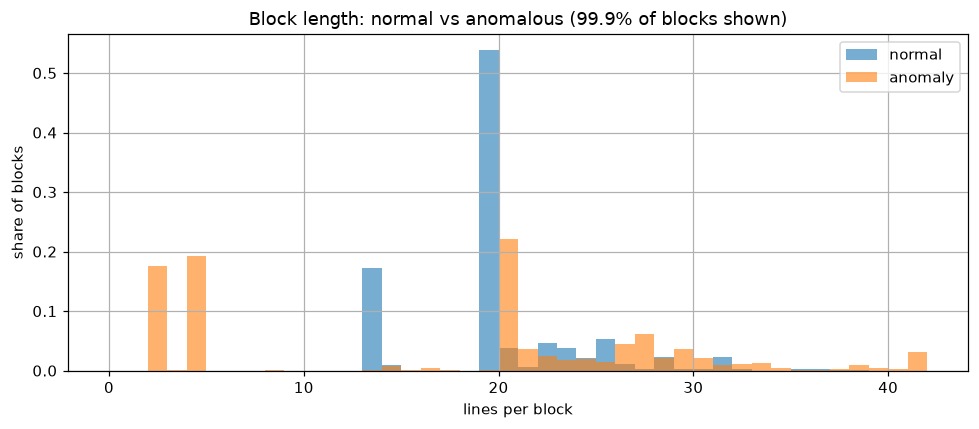

In [10]:
lengths = q("SELECT label, n_lines FROM blocks WHERE label IS NOT NULL")
fig, ax = plt.subplots()
bins = range(0, int(lengths["n_lines"].quantile(0.999)) + 2)
for value, name in [(0, "normal"), (1, "anomaly")]:
    ax.hist(
        lengths.loc[lengths["label"] == value, "n_lines"],
        bins=bins,
        density=True,
        alpha=0.6,
        label=name,
    )
ax.set_xlabel("lines per block")
ax.set_ylabel("share of blocks")
ax.set_title("Block length: normal vs anomalous (99.9% of blocks shown)")
ax.legend()
save(fig, "eda_block_length.png")

### 4b. Which kinds of message appear in anomalous blocks?

Messages differ only by IDs, IPs and numbers, e.g.
`Receiving block blk_123 src: /10.0.0.1:5000 dest: /10.0.0.2:50010`. As a **rough preview**
of Stage 2, we mask those variable parts with regular expressions to get a crude "template",
then compare how often each template shows up in normal vs anomalous blocks.

In [11]:
con.sql(r"""
    CREATE OR REPLACE TABLE block_templates AS
    SELECT DISTINCT group_id, label,
           regexp_replace(
               regexp_replace(
                   regexp_replace(message, 'blk_-?\d+', '<BLK>', 'g'),
                   '(\d+\.){3}\d+(:\d+)?', '<IP>', 'g'),
               '\d+', '<NUM>', 'g') AS template
    FROM logs
    WHERE group_id IS NOT NULL AND label IS NOT NULL
""")
enriched = q("""
    WITH totals AS (SELECT label, count(*) AS n FROM blocks WHERE label IS NOT NULL GROUP BY label)
    SELECT template,
           round(100 * count(*) FILTER (WHERE bt.label = 0) / any_value(t0.n), 2) AS pct_normal,
           round(100 * count(*) FILTER (WHERE bt.label = 1) / any_value(t1.n), 2) AS pct_anomalous
    FROM block_templates bt, totals t0, totals t1
    WHERE t0.label = 0 AND t1.label = 1
    GROUP BY template
    ORDER BY pct_anomalous - pct_normal DESC
""")
enriched.head(10)

,template,pct_normal,pct_anomalous
0,Unexpected error trying to delete block <BLK>....,0.04,30.44
1,Received block <BLK> src: /<IP> dest: /<IP> of...,0.32,20.58
2,<IP>:Transmitted block <BLK> to /<IP>,0.32,20.58
3,<IP> Starting thread to transfer block <BLK> t...,0.32,20.33
4,BLOCK* ask <IP> to replicate <BLK> to datanode...,0.32,20.33
5,writeBlock <BLK> received exception java.io.IO...,0.00,19.16
6,BLOCK* NameSystem.addStoredBlock: addStoredBlo...,0.00,7.41
7,BLOCK* NameSystem.allocateBlock: /user/root/ra...,6.26,13.48
8,BLOCK* NameSystem.addStoredBlock: Redundant ad...,0.00,5.77
9,BLOCK* NameSystem.allocateBlock: /user/root/ra...,12.52,15.42


Templates at the top are **much more common in anomalous blocks**, and some almost never
appear in normal ones. This is exactly the signal the models will learn from: in Stage 3 each
block becomes a vector of *how many times each template occurs*.

## 5. Why we need a real parser (Drain)

In [12]:
q(r"""
    SELECT count(DISTINCT message) AS distinct_messages,
           count(DISTINCT regexp_replace(regexp_replace(regexp_replace(message,
               'blk_-?\d+', '<BLK>', 'g'), '(\d+\.){3}\d+(:\d+)?', '<IP>', 'g'),
               '\d+', '<NUM>', 'g')) AS crude_templates
    FROM lines
""")

,distinct_messages,crude_templates
0,10335015,86


About 10 million distinct messages collapse into fewer than 100 patterns. (LogHub's hand-checked
answer for HDFS is 29 templates: our crude regexes still split some, e.g. one per output
folder `rand`, `randtxt`, ...) Hand-written regexes got us
close here, but they're fragile: they miss file paths, hostnames and new formats, and every new
log type would need new rules. **Drain** learns templates automatically from the logs
themselves, which is why it's Stage 2.

## 6. One normal block vs one anomalous block

In [13]:
def show_block(label):
    # Pick the first block (by ID) with this label and list its lines in order.
    block = q(f"SELECT min(group_id) AS g FROM blocks WHERE label = {label}")["g"][0]
    return q(f"""
        SELECT timestamp, level, component, message FROM logs
        WHERE group_id = '{block}' ORDER BY line_id
    """)


show_block(0)

,timestamp,level,component,message
0,2008-11-11 09:44:52,INFO,dfs.DataNode$DataXceiver,Receiving block blk_-1000002529962039464 src: ...
1,2008-11-11 09:44:52,INFO,dfs.DataNode$DataXceiver,Receiving block blk_-1000002529962039464 src: ...
2,2008-11-11 09:44:52,INFO,dfs.DataNode$DataXceiver,Receiving block blk_-1000002529962039464 src: ...
3,2008-11-11 09:44:52,INFO,dfs.FSNamesystem,BLOCK* NameSystem.allocateBlock: /user/root/ra...
4,2008-11-11 09:44:54,INFO,dfs.DataNode$PacketResponder,PacketResponder 2 for block blk_-1000002529962...
5,2008-11-11 09:44:54,INFO,dfs.DataNode$PacketResponder,Received block blk_-1000002529962039464 of siz...
6,2008-11-11 09:44:54,INFO,dfs.DataNode$PacketResponder,PacketResponder 0 for block blk_-1000002529962...
7,2008-11-11 09:44:54,INFO,dfs.DataNode$PacketResponder,Received block blk_-1000002529962039464 of siz...
8,2008-11-11 09:44:54,INFO,dfs.FSNamesystem,BLOCK* NameSystem.addStoredBlock: blockMap upd...
9,2008-11-11 09:44:54,INFO,dfs.FSNamesystem,BLOCK* NameSystem.addStoredBlock: blockMap upd...


In [14]:
show_block(1)

,timestamp,level,component,message
0,2008-11-11 08:17:14,INFO,dfs.DataNode$DataXceiver,Receiving block blk_-1000723577943457888 src: ...
1,2008-11-11 08:17:14,INFO,dfs.FSNamesystem,BLOCK* NameSystem.allocateBlock: /user/root/ra...
2,2008-11-11 08:17:16,INFO,dfs.DataNode$DataXceiver,Receiving block blk_-1000723577943457888 src: ...
3,2008-11-11 08:17:18,INFO,dfs.DataNode$DataXceiver,writeBlock blk_-1000723577943457888 received e...


## Takeaways

- **Size:** 11.2M lines, 575k blocks, covering about 38 hours (9–11 Nov 2008). DuckDB queries
  the 187 MB Parquet file in seconds.
- **No ERROR level:** only INFO (96.8%) and WARN (3.2%). Anomalies must be found from
  *patterns* of lines, not from a single error message.
- **Imbalanced:** 2.93% of blocks are anomalous (16,838 of 575,061). We evaluate with
  precision / recall / F1 on the anomaly class, never accuracy.
- **WARN alone is not enough:** 48% of anomalous blocks contain a WARN line, but so do 23%
  of normal ones. A "flag any WARN" rule would miss half the anomalies and raise many false alarms.
- **Short blocks are suspicious:** no normal block has fewer than 13 lines, but 36.8% of
  anomalous blocks do (often 2–5 lines: a block whose write failed early). Above 13 lines,
  length alone separates the classes poorly (median ~19–20 for both).
- **Some message types are strong signals:** e.g. *"Unexpected error trying to delete block …"*
  is in 30% of anomalous blocks and 0.04% of normal ones. Counting message types per block
  (Stage 3) should therefore work well.
- **Templates are essential:** ~10M distinct messages, but fewer than 100 patterns.

**Next (Stage 2):** parse every message into a template with Drain and save the templates
to `artifacts/hdfs/`.